**Holiday Package Prediction**<br>
**Problem Statement**
- 5 types of packages are there "Basic, Standard, Deluxe, Super Deluxe, King
- 18% of customers purchased the packages

**New Product - Wellness Tourism Package**
- To maintain enhance, kick start a healthy lifestyle


**Goal**<br>
Company wants to use the current data to make the marketing expenditure more efficient

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [9]:
# import kagglehub
# Download latest version
# kagglehub.dataset_download("susant4learning/holiday-package-purchase-prediction")

In [10]:
df=pd.read_csv("Travel.csv")
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [11]:
# Data Cleaning
# Handle Missing Values
# Handle Duplicates
# Check data types
# Understand the dataset

In [12]:
## We dont need customer id
df.drop(columns=["CustomerID"],inplace=True)

In [13]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ProdTaken                 4888 non-null   int64  
 1   Age                       4662 non-null   float64
 2   TypeofContact             4863 non-null   str    
 3   CityTier                  4888 non-null   int64  
 4   DurationOfPitch           4637 non-null   float64
 5   Occupation                4888 non-null   str    
 6   Gender                    4888 non-null   str    
 7   NumberOfPersonVisiting    4888 non-null   int64  
 8   NumberOfFollowups         4843 non-null   float64
 9   ProductPitched            4888 non-null   str    
 10  PreferredPropertyStar     4862 non-null   float64
 11  MaritalStatus             4888 non-null   str    
 12  NumberOfTrips             4748 non-null   float64
 13  Passport                  4888 non-null   int64  
 14  PitchSatisfactionSc

In [15]:
df.isnull().sum(axis=0)

ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [16]:
df.describe()

,ProdTaken,Age,CityTier,DurationOfPitch,NumberOfPersonVisiting,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome
count,4888.000000,4662.000000,4888.000000,4637.000000,4888.000000,4843.000000,4862.000000,4748.000000,4888.000000,4888.000000,4888.000000,4822.000000,4655.000000
mean,0.188216,37.622265,1.654255,15.490835,2.905074,3.708445,3.581037,3.236521,0.290917,3.078151,0.620295,1.187267,23619.853491
std,0.390925,9.316387,0.916583,8.519643,0.724891,1.002509,0.798009,1.849019,0.454232,1.365792,0.485363,0.857861,5380.698361
min,0.000000,18.000000,1.000000,5.000000,1.000000,1.000000,3.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1000.000000
25%,0.000000,31.000000,1.000000,9.000000,2.000000,3.000000,3.000000,2.000000,0.000000,2.000000,0.000000,1.000000,20346.000000
50%,0.000000,36.000000,1.000000,13.000000,3.000000,4.000000,3.000000,3.000000,0.000000,3.000000,1.000000,1.000000,22347.000000
75%,0.000000,44.000000,3.000000,20.000000,3.000000,4.000000,4.000000,4.000000,1.000000,4.000000,1.000000,2.000000,25571.000000
max,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,5.000000,1.000000,3.000000,98678.000000


In [17]:
## First I will remove the duplicate records
df.drop_duplicates(keep="first",ignore_index=True,inplace=True)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4747 entries, 0 to 4746
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ProdTaken                 4747 non-null   int64  
 1   Age                       4531 non-null   float64
 2   TypeofContact             4722 non-null   str    
 3   CityTier                  4747 non-null   int64  
 4   DurationOfPitch           4501 non-null   float64
 5   Occupation                4747 non-null   str    
 6   Gender                    4747 non-null   str    
 7   NumberOfPersonVisiting    4747 non-null   int64  
 8   NumberOfFollowups         4703 non-null   float64
 9   ProductPitched            4747 non-null   str    
 10  PreferredPropertyStar     4721 non-null   float64
 11  MaritalStatus             4747 non-null   str    
 12  NumberOfTrips             4609 non-null   float64
 13  Passport                  4747 non-null   int64  
 14  PitchSatisfactionSc

In [19]:
## Checking the Null Age Values and Imputing the Median Value
df[df["Age"].isnull()]

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
4,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0
11,0,NaN,Self Enquiry,1,21.0,Salaried,Female,2,4.0,Deluxe,3.0,Single,1.0,1,3,0,0.0,Manager,NaN
19,0,NaN,Self Enquiry,1,8.0,Salaried,Male,2,3.0,Basic,3.0,Single,6.0,1,4,0,1.0,Executive,NaN
20,0,NaN,Company Invited,1,17.0,Salaried,Female,3,2.0,Deluxe,3.0,Married,1.0,0,3,1,2.0,Manager,NaN
21,1,NaN,Self Enquiry,3,15.0,Salaried,Male,2,4.0,Deluxe,5.0,Single,1.0,0,2,0,0.0,Manager,18407.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2340,1,NaN,Self Enquiry,1,30.0,Small Business,Male,2,3.0,Basic,4.0,Married,2.0,1,1,0,0.0,Executive,NaN
2343,1,NaN,Self Enquiry,3,21.0,Small Business,Male,2,5.0,Deluxe,3.0,Married,7.0,1,1,0,1.0,Manager,18423.0
2357,1,NaN,Self Enquiry,3,22.0,Small Business,Male,3,3.0,Standard,3.0,Married,3.0,0,5,0,1.0,Senior Manager,18544.0
2360,1,NaN,Self Enquiry,1,14.0,Small Business,Female,3,3.0,Basic,5.0,Married,2.0,1,3,0,2.0,Executive,NaN


In [20]:
df["Age"].median()

np.float64(36.0)

In [21]:
df["Age"]=df["Age"].fillna(df["Age"].median())

In [22]:
df.isnull().sum()

ProdTaken                     0
Age                           0
TypeofContact                25
CityTier                      0
DurationOfPitch             246
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            44
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               138
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     60
Designation                   0
MonthlyIncome               224
dtype: int64

In [23]:
df.head()

,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [24]:
df["TypeofContact"].value_counts()

TypeofContact
Self Enquiry       3350
Company Invited    1372
Name: count, dtype: int64

In [25]:
# df[df["TypeofContact"].isnull()]
df.shape

(4747, 19)

In [26]:
# Since the count of NaN for TypeofContact is less -- around 25 -- proceeding to delete the records
df=df[df["TypeofContact"].notnull()].reset_index(drop=True)

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4722 entries, 0 to 4721
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ProdTaken                 4722 non-null   int64  
 1   Age                       4722 non-null   float64
 2   TypeofContact             4722 non-null   str    
 3   CityTier                  4722 non-null   int64  
 4   DurationOfPitch           4501 non-null   float64
 5   Occupation                4722 non-null   str    
 6   Gender                    4722 non-null   str    
 7   NumberOfPersonVisiting    4722 non-null   int64  
 8   NumberOfFollowups         4678 non-null   float64
 9   ProductPitched            4722 non-null   str    
 10  PreferredPropertyStar     4696 non-null   float64
 11  MaritalStatus             4722 non-null   str    
 12  NumberOfTrips             4584 non-null   float64
 13  Passport                  4722 non-null   int64  
 14  PitchSatisfactionSc

In [28]:
df.isnull().sum()

ProdTaken                     0
Age                           0
TypeofContact                 0
CityTier                      0
DurationOfPitch             221
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            44
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               138
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     60
Designation                   0
MonthlyIncome               199
dtype: int64

In [29]:
df["DurationOfPitch"].describe()

count    4501.000000
mean       15.510998
std         8.535634
min         5.000000
25%         9.000000
50%        13.000000
75%        20.000000
max       127.000000
Name: DurationOfPitch, dtype: float64

In [30]:
# For Duration of Pitch we can impute the median against the missing values
df["DurationOfPitch"]=df["DurationOfPitch"].fillna(df["DurationOfPitch"].median())

In [31]:
df.isnull().sum()

ProdTaken                     0
Age                           0
TypeofContact                 0
CityTier                      0
DurationOfPitch               0
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            44
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               138
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     60
Designation                   0
MonthlyIncome               199
dtype: int64

In [32]:
df["NumberOfFollowups"].describe()

count    4678.000000
mean        3.707354
std         1.006964
min         1.000000
25%         3.000000
50%         4.000000
75%         4.000000
max         6.000000
Name: NumberOfFollowups, dtype: float64

In [33]:
## Here we can impute with Median as well
## Actually we can impute Median here, but may or maynot impute a decimal value, hence we should check the discrete and continous columns first
## I see Number of Followups are in integer values

In [34]:
# Lets first now check the all the numerical and categorical columns and discrete and continous columns
cat_features=[feature for feature in df.columns if df[feature].dtype == "string"]
print(cat_features)
num_feaures=[feature for feature in df.columns if feature not in cat_features]
print(num_feaures)


['TypeofContact', 'Occupation', 'Gender', 'ProductPitched', 'MaritalStatus', 'Designation']
['ProdTaken', 'Age', 'CityTier', 'DurationOfPitch', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'MonthlyIncome']


In [35]:
df["ProdTaken"].unique()

array([1, 0])

In [36]:
discrete_features=[feature for feature in df.columns if len(df[feature].unique())<=25]
print(discrete_features)
discrete_numerical_feaures=[feature for feature in discrete_features if feature in num_feaures]
print(discrete_numerical_feaures)

['ProdTaken', 'TypeofContact', 'CityTier', 'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'Designation']
['ProdTaken', 'CityTier', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting']


In [37]:
# So for missing discrete numerical features mode will be the best value for imputation
# NumberOfFollowups can be imputed with mode
# PreferredPropertyStar can be imputed with mode
# NumberOfTrips can be imputed with mode
# NumberOfChildrenVisiting can be imputed with mode
# MonthlyIncome can be imputed with mean

In [38]:
df["MonthlyIncome"].describe()

count     4523.000000
mean     23602.239443
std       5385.503223
min       1000.000000
25%      20337.000000
50%      22311.000000
75%      25535.500000
max      98678.000000
Name: MonthlyIncome, dtype: float64

In [39]:
# Now before that -- lets check the categorical features values -- to check for redundant values
for feature in cat_features:
    print(df[feature].value_counts())

TypeofContact
Self Enquiry       3350
Company Invited    1372
Name: count, dtype: int64
Occupation
Salaried          2288
Small Business    2008
Large Business     424
Free Lancer          2
Name: count, dtype: int64
Gender
Male       2820
Female     1759
Fe Male     143
Name: count, dtype: int64
ProductPitched
Basic           1790
Deluxe          1669
Standard         714
Super Deluxe     324
King             225
Name: count, dtype: int64
MaritalStatus
Married      2264
Divorced      944
Single        871
Unmarried     643
Name: count, dtype: int64
Designation
Executive         1790
Manager           1669
Senior Manager     714
AVP                324
VP                 225
Name: count, dtype: int64


In [40]:
## 2 Columns are having redundant values
## Gender(Female, Fe Male) and MaritalStatus(Single,Unmarried) rest of the categories seems fine
# Lets first fix the categorical values

df["Gender"]=df["Gender"].str.replace("Fe Male","Female")
df["MaritalStatus"]=df["MaritalStatus"].str.replace("Single","Unmarried")

In [41]:
# Now before that -- lets check the categorical features values -- to check for redundant values
for feature in cat_features:
    print(df[feature].value_counts())

TypeofContact
Self Enquiry       3350
Company Invited    1372
Name: count, dtype: int64
Occupation
Salaried          2288
Small Business    2008
Large Business     424
Free Lancer          2
Name: count, dtype: int64
Gender
Male      2820
Female    1902
Name: count, dtype: int64
ProductPitched
Basic           1790
Deluxe          1669
Standard         714
Super Deluxe     324
King             225
Name: count, dtype: int64
MaritalStatus
Married      2264
Unmarried    1514
Divorced      944
Name: count, dtype: int64
Designation
Executive         1790
Manager           1669
Senior Manager     714
AVP                324
VP                 225
Name: count, dtype: int64


In [42]:
# Now imputing the missing value
# So for missing discrete numerical features mode will be the best value for imputation
# NumberOfFollowups can be imputed with mode
# PreferredPropertyStar can be imputed with mode
# NumberOfTrips can be imputed with mode
# NumberOfChildrenVisiting can be imputed with mode
# MonthlyIncome can be imputed with mean

mode_imputation=["NumberOfFollowups","PreferredPropertyStar","NumberOfTrips","NumberOfChildrenVisiting"]
for feature in mode_imputation:
    df[feature]=df[feature].fillna(df[feature].mode()[0])

In [43]:
df["MonthlyIncome"]=df["MonthlyIncome"].fillna(df["MonthlyIncome"].mean())

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4722 entries, 0 to 4721
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ProdTaken                 4722 non-null   int64  
 1   Age                       4722 non-null   float64
 2   TypeofContact             4722 non-null   str    
 3   CityTier                  4722 non-null   int64  
 4   DurationOfPitch           4722 non-null   float64
 5   Occupation                4722 non-null   str    
 6   Gender                    4722 non-null   str    
 7   NumberOfPersonVisiting    4722 non-null   int64  
 8   NumberOfFollowups         4722 non-null   float64
 9   ProductPitched            4722 non-null   str    
 10  PreferredPropertyStar     4722 non-null   float64
 11  MaritalStatus             4722 non-null   str    
 12  NumberOfTrips             4722 non-null   float64
 13  Passport                  4722 non-null   int64  
 14  PitchSatisfactionSc

In [45]:
df.isnull().sum()

ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [46]:
## Feauture Engineering, First lets define the independent and dependent variable
y=df["ProdTaken"]
X=df.iloc[:,1:]

In [47]:
X["TotalPersonVisiting"]=X["NumberOfPersonVisiting"]+X["NumberOfChildrenVisiting"]
X.drop(columns=["NumberOfPersonVisiting","NumberOfChildrenVisiting"],inplace=True)

In [48]:
## Test Train Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=10)

In [49]:
X_train.head()

,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalPersonVisiting
3461,39.0,Self Enquiry,1,9.0,Small Business,Male,4.0,Deluxe,4.0,Married,6.0,0,4,0,Manager,23533.000000,4.0
4368,48.0,Self Enquiry,1,9.0,Salaried,Female,4.0,Super Deluxe,3.0,Married,3.0,1,4,1,AVP,35430.000000,4.0
3476,24.0,Self Enquiry,1,17.0,Large Business,Male,2.0,Basic,3.0,Married,4.0,0,1,1,Executive,20751.000000,4.0
613,36.0,Self Enquiry,3,6.0,Small Business,Male,1.0,Deluxe,5.0,Married,2.0,0,4,0,Manager,23602.239443,2.0
3287,59.0,Self Enquiry,1,30.0,Salaried,Male,4.0,Basic,3.0,Married,3.0,0,3,1,Executive,21050.000000,5.0


In [50]:
y

0       1
1       0
2       1
3       0
4       0
       ..
4717    1
4718    1
4719    1
4720    1
4721    1
Name: ProdTaken, Length: 4722, dtype: int64

In [51]:
## Encoding
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler
from sklearn.compose import ColumnTransformer

In [52]:
for feature in cat_features:
    print(feature)
    print(len(X_train[feature].unique()))

TypeofContact
2
Occupation
4
Gender
2
ProductPitched
5
MaritalStatus
3
Designation
5


In [53]:
## Lets Label Encode Designation and ProductPitched and rest of them we can one hot encode
## We also need to standard scale the continous numerical features

In [54]:
le_features=["Designation","ProductPitched"]
ohe_features=["TypeofContact","Occupation","Gender","MaritalStatus"]
con_num_features=[feature for feature in num_feaures if len(df[feature].unique())>=25]
print(con_num_features)

['Age', 'DurationOfPitch', 'MonthlyIncome']


In [55]:
le=LabelEncoder()
for feature in le_features:
    X_train[feature]=le.fit_transform(X_train[feature])
    X_test[feature]=le.transform(X_test[feature])
transformer=[
    ("OneHot_Encoding",OneHotEncoder(drop="first"),ohe_features),
    ("Standard_Scaler",StandardScaler(),con_num_features)
]
ct=ColumnTransformer(transformers=transformer,remainder="passthrough",n_jobs=-1)

In [56]:
X_train.head()

,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,Designation,MonthlyIncome,TotalPersonVisiting
3461,39.0,Self Enquiry,1,9.0,Small Business,Male,4.0,1,4.0,Married,6.0,0,4,0,2,23533.000000,4.0
4368,48.0,Self Enquiry,1,9.0,Salaried,Female,4.0,4,3.0,Married,3.0,1,4,1,0,35430.000000,4.0
3476,24.0,Self Enquiry,1,17.0,Large Business,Male,2.0,0,3.0,Married,4.0,0,1,1,1,20751.000000,4.0
613,36.0,Self Enquiry,3,6.0,Small Business,Male,1.0,1,5.0,Married,2.0,0,4,0,2,23602.239443,2.0
3287,59.0,Self Enquiry,1,30.0,Salaried,Male,4.0,0,3.0,Married,3.0,0,3,1,1,21050.000000,5.0


In [57]:
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

In [58]:
pd.DataFrame(X_train)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.156429,-0.788843,-0.010448,1.0,4.0,1.0,4.0,6.0,0.0,4.0,0.0,2.0,4.0
1,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.143994,-0.788843,2.301369,1.0,4.0,4.0,3.0,3.0,1.0,4.0,1.0,0.0,4.0
2,1.0,1.0,0.0,0.0,1.0,1.0,0.0,-1.489513,0.198230,-0.551044,1.0,2.0,0.0,3.0,4.0,0.0,1.0,1.0,1.0,4.0
3,1.0,0.0,0.0,1.0,1.0,1.0,0.0,-0.172760,-1.158995,0.003007,3.0,1.0,1.0,5.0,2.0,0.0,4.0,0.0,2.0,2.0
4,1.0,0.0,1.0,0.0,1.0,1.0,0.0,2.351017,1.802223,-0.492943,1.0,4.0,0.0,3.0,3.0,0.0,3.0,1.0,1.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3536,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.046699,-0.912227,-1.194436,1.0,4.0,0.0,4.0,2.0,0.0,1.0,1.0,1.0,2.0
3537,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.924535,2.419143,-0.539579,1.0,4.0,0.0,3.0,6.0,0.0,3.0,1.0,1.0,7.0
3538,1.0,0.0,0.0,1.0,0.0,1.0,0.0,-0.392218,-0.788843,-0.094005,3.0,4.0,1.0,3.0,4.0,1.0,3.0,0.0,2.0,3.0
3539,1.0,0.0,1.0,0.0,0.0,1.0,0.0,-1.379783,1.061918,-0.524423,1.0,4.0,0.0,4.0,3.0,0.0,1.0,1.0,1.0,7.0


In [59]:
ct.get_feature_names_out()

array(['OneHot_Encoding__TypeofContact_Self Enquiry',
       'OneHot_Encoding__Occupation_Large Business',
       'OneHot_Encoding__Occupation_Salaried',
       'OneHot_Encoding__Occupation_Small Business',
       'OneHot_Encoding__Gender_Male',
       'OneHot_Encoding__MaritalStatus_Married',
       'OneHot_Encoding__MaritalStatus_Unmarried', 'Standard_Scaler__Age',
       'Standard_Scaler__DurationOfPitch',
       'Standard_Scaler__MonthlyIncome', 'remainder__CityTier',
       'remainder__NumberOfFollowups', 'remainder__ProductPitched',
       'remainder__PreferredPropertyStar', 'remainder__NumberOfTrips',
       'remainder__Passport', 'remainder__PitchSatisfactionScore',
       'remainder__OwnCar', 'remainder__Designation',
       'remainder__TotalPersonVisiting'], dtype=object)

In [60]:
## GradientBoost Model
## Model Training

In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_score,recall_score,f1_score,roc_auc_score,roc_curve
from sklearn.ensemble import AdaBoostClassifier

In [62]:
models={
    "Logistic Regression":LogisticRegression(),
    "SVC":SVC(),
    "KNeighborsClassifier":KNeighborsClassifier(),
    "DecisionTreeClassifier":DecisionTreeClassifier(),
    "RandomForestClassifier":RandomForestClassifier(),
    "AdaBoostClassifier":AdaBoostClassifier(),
    "GradientBoostingClassifier":GradientBoostingClassifier()
}

In [ ]:
for name,model in models.items():
    model.fit(X_train,y_train)

    # Make Prediction
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    # Train Data Performance
    print("-"*50)
    print("Model Name =",name)
    print("-"*50)
    print("Test Data Performance")
    print(f"{accuracy_score(y_train,y_train_pred) = :.2f}")
    print(f"{precision_score(y_train,y_train_pred) = :.2f}")
    print(f"{recall_score(y_train,y_train_pred) = :.2f}")
    print(f"{f1_score(y_train,y_train_pred,average="weighted") = :.2f}")
    print(f"{roc_auc_score(y_train,y_train_pred) = :.2f}")
    # print("Confustion Matrix")
    # print(confusion_matrix(y_train,y_train_pred))
    # print(classification_report(y_train,y_train_pred))
    print()
    # Test Data Performance
    print("Test Data Performance")
    print(f"{accuracy_score(y_test,y_test_pred) = :.2f}")
    print(f"{precision_score(y_test,y_test_pred) = :.2f}")
    print(f"{recall_score(y_test,y_test_pred) = :.2f}")
    print(f"{f1_score(y_test,y_test_pred,average="weighted") = :.2f}")
    print(f"{roc_auc_score(y_test,y_test_pred) = :.2f}")
    # print("Confustion Matrix")
    # print(confusion_matrix(y_test,y_test_pred))
    # print(classification_report(y_test,y_test_pred))

--------------------------------------------------
Model Name = Logistic Regression
--------------------------------------------------
Test Data Performance
accuracy_score(y_train,y_train_pred) = 0.84
precision_score(y_train,y_train_pred) = 0.70
recall_score(y_train,y_train_pred) = 0.29
f1_score(y_train,y_train_pred) = 0.41
roc_auc_score(y_train,y_train_pred) = 0.63

Test Data Performance
accuracy_score(y_test,y_test_pred) = 0.86
precision_score(y_test,y_test_pred) = 0.63
recall_score(y_test,y_test_pred) = 0.32
f1_score(y_test,y_test_pred) = 0.42
roc_auc_score(y_test,y_test_pred) = 0.64
--------------------------------------------------
Model Name = SVC
--------------------------------------------------
Test Data Performance
accuracy_score(y_train,y_train_pred) = 0.83
precision_score(y_train,y_train_pred) = 0.90
recall_score(y_train,y_train_pred) = 0.18
f1_score(y_train,y_train_pred) = 0.30
roc_auc_score(y_train,y_train_pred) = 0.59

Test Data Performance
accuracy_score(y_test,y_test_p

In [64]:
rf_params={
    "max_depth":[5,8,15,None,10],
    "n_estimators":[100,200,500,1000],
    "min_samples_split":[2,8,15,20],
    "max_features":[5,7,"auto",8]
}
adaboost_param={
    "n_estimators":[50,60,70,80,90]
}
gradient_param={
    "loss":["log_loss", "exponential"],
    "n_estimators":[100,200,500,1000],
    "criterion":["friedman_mse", "squared_error"],
    "min_samples_split":[2,8,15,20],
    "max_depth":[5,8,15,None,10]
}

In [65]:
## Hyperparameter Tuning
from sklearn.model_selection import RandomizedSearchCV
randomcv_models=[
    ("RF",RandomForestClassifier(),rf_params),
    ("AB",AdaBoostClassifier(),adaboost_param),
    ("GB",GradientBoostingClassifier(),gradient_param)
]

In [66]:
model_param={}
for name,model,param in randomcv_models:
    random=RandomizedSearchCV(estimator=model,param_distributions=param,n_iter=100,cv=3,n_jobs=-1,verbose=2)
    random.fit(X_train,y_train)
    model_param[name]=random.best_params_

for name,param in model_param.items():
    print(f"Best Param for {name} is ")
    print(param)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Param for RF is 
{'n_estimators': 200, 'min_samples_split': 2, 'max_features': 7, 'max_depth': None}
Best Param for AB is 
{'n_estimators': 50}
Best Param for GB is 
{'n_estimators': 200, 'min_samples_split': 8, 'max_depth': 10, 'loss': 'log_loss', 'criterion': 'friedman_mse'}


In [69]:
models={
    "RandomForestClassifier":RandomForestClassifier(n_estimators=200, min_samples_split=2, max_features=7, max_depth=None),
    "AdaBoostClassifier":AdaBoostClassifier(n_estimators=50),
    "GradientBoostingClassifier":GradientBoostingClassifier(loss="log_loss",n_estimators=200,criterion="friedman_mse",min_samples_split=8,max_depth=10)
}

In [70]:
for name,model in models.items():
    model.fit(X_train,y_train)

    # Make Prediction
    y_train_pred=model.predict(X_train)
    y_test_pred=model.predict(X_test)

    # Train Data Performance
    print("-"*50)
    print("Model Name =",name)
    print("-"*50)
    print("Test Data Performance")
    print(f"{accuracy_score(y_train,y_train_pred) = :.2f}")
    print(f"{precision_score(y_train,y_train_pred) = :.2f}")
    print(f"{recall_score(y_train,y_train_pred) = :.2f}")
    print(f"{f1_score(y_train,y_train_pred,average="weighted") = :.2f}")
    print(f"{roc_auc_score(y_train,y_train_pred) = :.2f}")
    # print("Confustion Matrix")
    # print(confusion_matrix(y_train,y_train_pred))
    # print(classification_report(y_train,y_train_pred))
    print()
    # Test Data Performance
    print("Test Data Performance")
    print(f"{accuracy_score(y_test,y_test_pred) = :.2f}")
    print(f"{precision_score(y_test,y_test_pred) = :.2f}")
    print(f"{recall_score(y_test,y_test_pred) = :.2f}")
    print(f"{f1_score(y_test,y_test_pred,average="weighted") = :.2f}")
    print(f"{roc_auc_score(y_test,y_test_pred) = :.2f}")
    # print("Confustion Matrix")
    # print(confusion_matrix(y_test,y_test_pred))
    # print(classification_report(y_test,y_test_pred))

--------------------------------------------------
Model Name = RandomForestClassifier
--------------------------------------------------
Test Data Performance
accuracy_score(y_train,y_train_pred) = 1.00
precision_score(y_train,y_train_pred) = 1.00
recall_score(y_train,y_train_pred) = 1.00
f1_score(y_train,y_train_pred,average="weighted") = 1.00
roc_auc_score(y_train,y_train_pred) = 1.00

Test Data Performance
accuracy_score(y_test,y_test_pred) = 0.95
precision_score(y_test,y_test_pred) = 0.92
recall_score(y_test,y_test_pred) = 0.79
f1_score(y_test,y_test_pred,average="weighted") = 0.95
roc_auc_score(y_test,y_test_pred) = 0.89
--------------------------------------------------
Model Name = AdaBoostClassifier
--------------------------------------------------
Test Data Performance
accuracy_score(y_train,y_train_pred) = 0.84
precision_score(y_train,y_train_pred) = 0.77
recall_score(y_train,y_train_pred) = 0.28
f1_score(y_train,y_train_pred,average="weighted") = 0.81
roc_auc_score(y_train

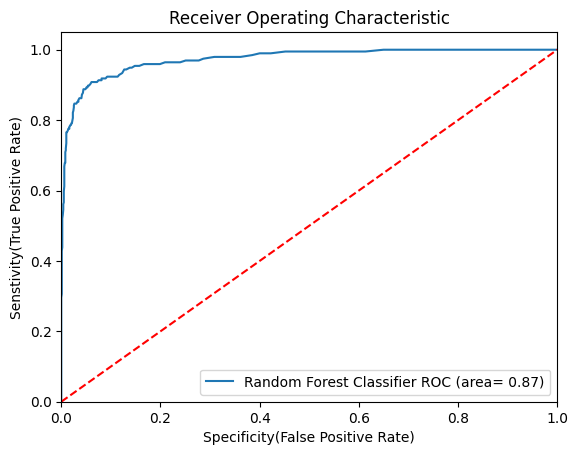

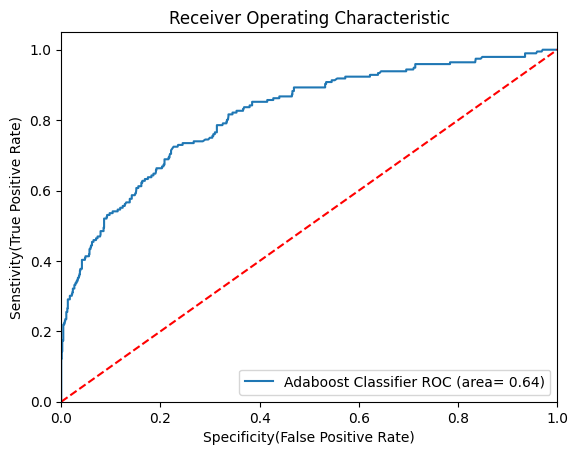

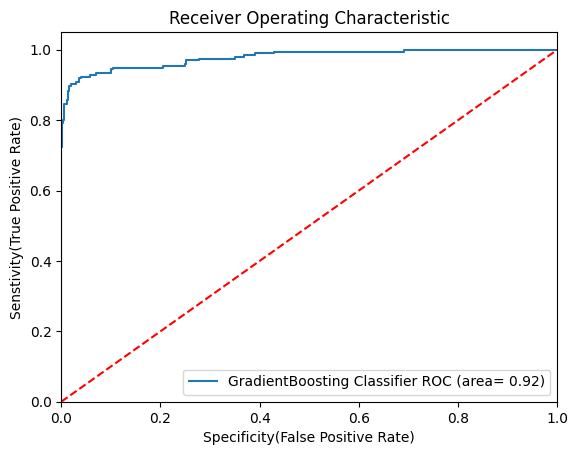

In [71]:
## ROC AUC Curve
from sklearn.metrics import roc_auc_score,roc_curve
plt.figure()

# Add the model to the list that you want to view the ROC AUC Curve
auc_models=[
    {
        "label":"Random Forest Classifier",
        "model":RandomForestClassifier(n_estimators=200, min_samples_split=2, max_features=7, max_depth=None),
        "auc":0.87
    },
    {
        "label":"Adaboost Classifier",
        "model":AdaBoostClassifier(n_estimators=50),
        "auc":0.64
    },
    {
        "label":"GradientBoosting Classifier",
        "model":GradientBoostingClassifier(loss="log_loss",n_estimators=200,criterion="friedman_mse",min_samples_split=8,max_depth=10),
        "auc":0.92
    }
]

# Create loop through all model
t=1
for algo in auc_models:
    model=algo["model"] # select the model
    model.fit(X_train,y_train) # Train the model
    #Computer False Positive rate and true positive rate
    fpr,tpr,thresholds=roc_curve(y_test,model.predict_proba(X_test)[:,1])
    # Calculate Area under curve to display plot
    plt.plot(fpr,tpr,label="%s ROC (area= %0.2f)"%(algo["label"],algo["auc"]))
    #Custom Settings for plot
    plt.plot([0,1],[0,1],"r--")
    plt.xlim([0.0,1.0])
    plt.ylim([0.0,1.05])
    plt.xlabel("Specificity(False Positive Rate)")
    plt.ylabel("Senstivity(True Positive Rate)")
    plt.title("Receiver Operating Characteristic")
    plt.legend(loc="lower right")
    plt.savefig(f"auc_{t}.png")
    t=t+1
    plt.show()